# Section 5.2: COVID-19 Vaccine Conjoint Analysis (Wang et al., 2026 Benchmark)

This notebook dynamically discovers all collected generative LLM and decision-model choice datasets on the Kreps et al. (2020) / Wang et al. (2026) COVID-19 vaccine conjoint benchmark, estimates multinomial logit (MNL) part-worth utilities via maximum likelihood, prints the formatted Markdown tables (`#tbl-wang-mnl` and `#apptbl-wang-coefs`), and saves the publication figures (`wang_mnl_random.pdf`, `wang_mnl_persona.pdf`, and `wang_mnl_coefs.pdf`) directly in `code/analysis/wang2026/`.

## 1. Setup & Ground-Truth Human MNL Estimation

In [1]:
import importlib
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wang_mnl

importlib.reload(wang_mnl)
from wang_mnl import (
    AUDIT_PREFIX,
    build_wang_coef_table,
    build_wang_summary_table,
    encode_design_matrix,
    evaluate_wang_metrics,
    fit_mnl_mle,
    load_all_model_regressions,
    load_covid_conjoint,
    pair_choice_sets,
)

# --- Design ---
DATA_PATH = Path("../../data/covid/dataverse_files/Kreps_etal_vax_replication_data.dta")
OUT_DIR = Path(".").resolve()

# Evaluation subsample (must match the collection notebooks)
N_RESPONDENTS = 200
SUBSAMPLE_SEED = 42

# Generative LLM runs: (model, thinking level), each with random and respondent-persona files
GEMINI_DIR = "../../proprietary-llms/gemini/data"
GEMINI_RUNS = [
    ("gemini-3.5-flash-lite", "MINIMAL"),
    ("gemini-3.5-flash-lite", "HIGH"),
    ("gemini-4-argon", "LOW"),
    ("gemini-4-argon", "HIGH"),
]

# Kev checkpoints (record `model` field)
KEV_MODEL_IDS = ["jaredpalmer/kev-9b", "kev-9b-resp-issp+twin2k-grouped-newvalid/best"]
# Kev run sets: (label prefix, folder, prompt wording); "wang" = @wang2026large wording shared with the generative LLMs,
# "survey" = audited survey instrument. Add ("audit-", "data-audit", "survey") next to ("", "data", "wang") to compare both.
KEV_RUN_SETS = [
    ("", "data-audit", "survey"),
]
# Label prefix of the Kev run set drawn in the coefficient figure
FIG_KEV_PREFIX = ""

# Persona attributes in the prompts. Kev: the collection notebook's PERSONA_COLS. Gemini: DATASET_PERSONA_COLS["covid"]
# in the Gemini notebook (current persona.py), which also states country; Gemini records do not store them.
KEV_PERSONA_COLS = ("US_REG", "SEX", "AGE", "EDULEVEL", "RELIGGRP", "PARTY_LR", "US_PRTY", "US_INC", "RACE")
GEMINI_PERSONA_COLS = ("c_alphan",) + KEV_PERSONA_COLS

raw_df = load_covid_conjoint(DATA_PATH)
df_A, df_B, y_human_A, y_human_B, y_human_C = pair_choice_sets(raw_df)
X_A = encode_design_matrix(df_A)
X_B = encode_design_matrix(df_B)

print(f"Loaded {len(df_A):,} paired choice sets across {df_A['respondent'].nunique():,} respondents (d={X_A.shape[1]} features)")

# Fit full-sample human ground-truth MNL regression (beta*, N = 9,855 pairs)
human_mnl_df = fit_mnl_mle(X_A, X_B, y_human_A, y_human_B, y_human_C)
beta_star = human_mnl_df["beta"].copy()

# Subsample N_RESPONDENTS respondents (seed SUBSAMPLE_SEED) and fit Human Subsample Baseline MNL (beta_sub)
all_respondents = np.sort(df_A["respondent"].unique())
rng = np.random.default_rng(SUBSAMPLE_SEED)
sampled_respondents = np.sort(rng.choice(all_respondents, size=N_RESPONDENTS, replace=False))

sub_mask = df_A["respondent"].isin(sampled_respondents).to_numpy()
sub_df_A = df_A.loc[sub_mask].reset_index(drop=True)
sub_df_B = df_B.loc[sub_mask].reset_index(drop=True)
X_A_sub = X_A[sub_mask]
X_B_sub = X_B[sub_mask]
y_human_A_sub = y_human_A[sub_mask]
y_human_B_sub = y_human_B[sub_mask]
y_human_C_sub = y_human_C[sub_mask]

subsample_keys = [(int(r["respondent"]), int(r["pair_id"])) for r in sub_df_A[["respondent", "pair_id"]].to_dict("records")]

# Sample sizes used in table/figure labels and notes
n_full_resp, n_full_sets = df_A["respondent"].nunique(), len(df_A)
n_sub_resp, n_sub_sets, d_attr = len(sampled_respondents), len(sub_df_A), X_A.shape[1]

human_sub_mnl_df = fit_mnl_mle(X_A_sub, X_B_sub, y_human_A_sub, y_human_B_sub, y_human_C_sub)
beta_human_sub = human_sub_mnl_df["beta"].copy()
human_sub_metrics = evaluate_wang_metrics(beta_human_sub, beta_star)

print(
    f"Human Subsample Baseline (n={len(sub_df_A):,} pairs) vs. Full Human (beta*): "
    f"MAPE = {human_sub_metrics['MAPE (%)']:.2f}%, MSE = {human_sub_metrics['MSE']:.4f}"
)

Loaded 9,855 paired choice sets across 1,971 respondents (d=11 features)
Human Subsample Baseline (n=1,000 pairs) vs. Full Human (beta*): MAPE = 22.08%, MSE = 0.0065


## 2. Dynamic Discovery of Model Predictions & MNL Estimation

In [2]:
gemini_mnl_dfs = load_all_model_regressions(
    X_A_sub, X_B_sub, subsample_keys,
    gemini_data_dir=GEMINI_DIR, gemini_runs=GEMINI_RUNS, kev_data_dir=None, kev_model_ids=[],
)
kev_mnl_dfs_by_prefix = {
    prefix: load_all_model_regressions(
        X_A_sub, X_B_sub, subsample_keys,
        gemini_data_dir=None, gemini_runs=[], kev_data_dir=folder, kev_model_ids=KEV_MODEL_IDS, kev_label_prefix=prefix,
    )
    for prefix, folder, _ in KEV_RUN_SETS
}
model_mnl_dfs = dict(gemini_mnl_dfs)
for kev_dfs in kev_mnl_dfs_by_prefix.values():
    if set(kev_dfs) & set(model_mnl_dfs):
        raise ValueError(f"Duplicate labels across run sets: {sorted(set(kev_dfs) & set(model_mnl_dfs))}")
    model_mnl_dfs.update(kev_dfs)
print(f"Dynamically loaded and fitted {len(model_mnl_dfs)} model datasets:")
for name in model_mnl_dfs:
    print(" -", name)

human_sub_key = f"Human Subsample Baseline (n={len(sub_df_A)})"
estimators_beta = {
    human_sub_key: beta_human_sub,
    **{name: df_m["beta"] for name, df_m in model_mnl_dfs.items()},
}

comparison_rows = {}
for name, b_hat in estimators_beta.items():
    vs_full = evaluate_wang_metrics(b_hat, beta_star)
    vs_sub = evaluate_wang_metrics(b_hat, beta_human_sub)
    comparison_rows[name] = {
        "MAPE vs. Full Human (%)": vs_full["MAPE (%)"],
        "MSE vs. Full Human": vs_full["MSE"],
        "MAPE vs. Human Subsample (%)": vs_sub["MAPE (%)"],
        "MSE vs. Human Subsample": vs_sub["MSE"],
    }

comparison_metrics_df = pd.DataFrame(comparison_rows).T.sort_values("MSE vs. Full Human", ascending=True)

[WARNING] gemini-4-argon_HIGH_random.jsonl: dropped 16/1000 non-A/B/C refusal responses (fitting on valid n=984; first 3 refusal keys: [(112, 5), (530, 2), (581, 5)])
Dynamically loaded and fitted 12 model datasets:
 - gemini-3.5-flash-lite (MINIMAL, Random Persona, n=1000)
 - gemini-3.5-flash-lite (MINIMAL, Respondent Persona, n=1000)
 - gemini-3.5-flash-lite (HIGH, Random Persona, n=1000)
 - gemini-3.5-flash-lite (HIGH, Respondent Persona, n=1000)
 - gemini-4-argon (LOW, Random Persona, n=1000)
 - gemini-4-argon (LOW, Respondent Persona, n=1000)
 - gemini-4-argon (HIGH, Random Persona, n=984)
 - gemini-4-argon (HIGH, Respondent Persona, n=1000)
 - jaredpalmer/kev-9b (Random Persona, n=1000)
 - jaredpalmer/kev-9b (Respondent Persona, n=1000)
 - kev-9b-resp-issp+twin2k-grouped-newvalid/best (Random Persona, n=1000)
 - kev-9b-resp-issp+twin2k-grouped-newvalid/best (Respondent Persona, n=1000)


## 3. Main-Text Table: MNL Part-Worth Recovery (`#tbl-wang-mnl`)

In [3]:
import json
import sys

from wang_mnl import format_raw_model_name, parse_entry_metadata

CODE_DIR = Path("../..").resolve()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
from data.persona import PERSONA_NAMES

def to_paper_md(df: pd.DataFrame) -> str:
    """Compact pipe table (first column left, others right) with italic n/N, matching manuscript.qmd."""
    rows = [list(df.columns)] + [[str(v) for v in r] for r in df.itertuples(index=False)]
    lines = ["| " + " | ".join(r) + " |" for r in rows]
    lines.insert(1, "|:---|" + "---:|" * (len(df.columns) - 1))
    md = "\n".join(lines)
    return md.replace("(n = ", "(*n* = ").replace("(N = ", "(*N* = ").replace("random n = ", "random *n* = ")


def kev_temperatures(data_dir: str) -> dict[str, float]:
    """Read the inference temperature recorded in each Kev JSONL (model id -> T)."""
    temps: dict[str, float] = {}
    for path in sorted(Path(data_dir).glob("*.jsonl")):
        with path.open(encoding="utf-8") as f:
            rec = json.loads(f.readline())
        model_id = str(rec["model"])
        if model_id in temps and temps[model_id] != float(rec["temperature"]):
            raise ValueError(f"{path}: temperature differs from other runs of {model_id}")
        temps[model_id] = float(rec["temperature"])
    return temps


# Inference temperature per Kev checkpoint, identical across run sets
kev_T = kev_temperatures(KEV_RUN_SETS[0][1])
for _, folder, _ in KEV_RUN_SETS[1:]:
    if kev_temperatures(folder) != kev_T:
        raise ValueError(f"{folder}: Kev temperatures differ from {KEV_RUN_SETS[0][1]}")
temp_txt = "; ".join(f"`{format_raw_model_name(m)}` at $T = {kev_T[m]:.2f}$" for m in KEV_MODEL_IDS)

# Persona attributes in the prompts (declared in the design cell)
gemini_extra = [PERSONA_NAMES[c].lower() for c in GEMINI_PERSONA_COLS if c not in KEV_PERSONA_COLS]
persona_txt = (
    f"Respondent personas comprise {len(KEV_PERSONA_COLS)} demographic and political attributes"
    + (f" (generative LLM prompts additionally state {', '.join(gemini_extra)})" if gemini_extra else "")
)

# Prompt wording of each Kev run set
PROMPT_WORDING_TXT = {
    "wang": "the @wang2026large prompt wording shared with the generative LLMs",
    "survey": "the question wording, option labels, and attribute descriptions of the original survey instrument [@kreps2020factors]",
}
wording_parts = []
for prefix, _, wording in KEV_RUN_SETS:
    rows = f"`{prefix}` Kev rows" if prefix else ("Unprefixed Kev rows" if len(KEV_RUN_SETS) > 1 else "Kev rows")
    wording_parts.append(f"{rows} use {PROMPT_WORDING_TXT[wording]}")
if all(w != "wang" for _, _, w in KEV_RUN_SETS):
    wording_parts.append("the generative LLMs are prompted with the @wang2026large wording")
wording_txt = "; ".join(wording_parts)

short_runs = [parse_entry_metadata(k) for k in comparison_metrics_df.index if k != human_sub_key]
short_runs = [m for m in short_runs if int(m["n"]) < n_sub_sets]
refusal_txt = "; ".join(
    f"*n* = {int(m['n']):,} for `{m['model']}` under {m['persona'].lower()}s due to {n_sub_sets - int(m['n'])} non-A/B/C refusals"
    for m in short_runs
)

tbl_wang_df = build_wang_summary_table(comparison_metrics_df, human_sub_key=human_sub_key, n_sub_sets=n_sub_sets)
display(tbl_wang_df)

print(to_paper_md(tbl_wang_df))
print("\n: Multinomial logit part-worth parameter recovery on the COVID-19 vaccine conjoint benchmark {#tbl-wang-mnl}\n")
print('::: {custom-style="Table Note"}')
print(
    f"*Note.* Mean Absolute Percentage Error (MAPE) and Mean Squared Error (MSE) are computed across $d = {d_attr}$ vaccine attribute indicators "
    f"on the {n_sub_resp}-respondent evaluation subsample (*n* = {n_sub_sets:,} choice sets{'; ' + refusal_txt if refusal_txt else ''}), "
    f"benchmarked against the full-sample human MNL estimate $\\boldsymbol{{\\beta}}^*$ (*N* = {n_full_resp:,} respondents, {n_full_sets:,} choice sets; "
    f"@kreps2020factors; @wang2026large). {persona_txt}. Decision models plug continuous choice probabilities into the MNL log-likelihood "
    f"({temp_txt}). {wording_txt[0].upper() + wording_txt[1:]}."
)
print(":::")

,Estimator,Random persona MAPE (%),Random persona MSE,Respondent persona MAPE (%),Respondent persona MSE
0,"Human subsample (n = 1,000)",—,—,22.1%,0.0065
1,Kev 9B FT,84.0%,0.0875,56.4%,0.0267
2,Kev 9B (base),135.4%,0.2449,93.5%,0.0815
3,Gemini 3.5 Flash-Lite (minimal),531.7%,3.2073,203.6%,0.5925
4,Gemini 3.5 Flash-Lite (high),998.2%,14.4555,335.8%,1.1984
5,Gemini 4 Argon (low),1394.3%,23.3998,376.7%,1.7637
6,Gemini 4 Argon (high) (random n = 984),1507.7%,26.2179,395.1%,2.1687


| Estimator | Random persona MAPE (%) | Random persona MSE | Respondent persona MAPE (%) | Respondent persona MSE |
|:---|---:|---:|---:|---:|
| Human subsample (*n* = 1,000) | — | — | 22.1% | 0.0065 |
| Kev 9B FT | 84.0% | 0.0875 | 56.4% | 0.0267 |
| Kev 9B (base) | 135.4% | 0.2449 | 93.5% | 0.0815 |
| Gemini 3.5 Flash-Lite (minimal) | 531.7% | 3.2073 | 203.6% | 0.5925 |
| Gemini 3.5 Flash-Lite (high) | 998.2% | 14.4555 | 335.8% | 1.1984 |
| Gemini 4 Argon (low) | 1394.3% | 23.3998 | 376.7% | 1.7637 |
| Gemini 4 Argon (high) (random *n* = 984) | 1507.7% | 26.2179 | 395.1% | 2.1687 |

: Multinomial logit part-worth parameter recovery on the COVID-19 vaccine conjoint benchmark {#tbl-wang-mnl}

::: {custom-style="Table Note"}
*Note.* Mean Absolute Percentage Error (MAPE) and Mean Squared Error (MSE) are computed across $d = 11$ vaccine attribute indicators on the 200-respondent evaluation subsample (*n* = 1,000 choice sets; *n* = 984 for `Gemini 4 Argon (high)` under random personas due 

## 4. Main-Text Figures: Random Persona & Respondent Persona MNL Recovery (`wang_mnl_random.pdf`, `wang_mnl_persona.pdf`)

In [16]:
import re

from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

from wang_mnl import PALETTES, set_academic_palette, format_entry_display_label, format_raw_model_name, parse_entry_metadata, MODEL_PALETTES, NEUTRALS

# Bar groups for the error figures: one group per Kev size (each checkpoint followed by its run-set counterparts),
# then one group per Gemini model (thinking levels in GEMINI_RUNS order)
ERROR_PLOT_GROUPS: dict[str, list[str]] = {}
for model_id in KEV_MODEL_IDS:
    display_name = format_raw_model_name(model_id)
    size = re.match(r"Kev [\d.]+B", display_name).group(0)
    ERROR_PLOT_GROUPS.setdefault(size, []).extend(prefix + display_name for prefix, _, _ in KEV_RUN_SETS)
for model_id, thinking_level in GEMINI_RUNS:
    ERROR_PLOT_GROUPS.setdefault(format_raw_model_name(model_id), []).append(
        format_raw_model_name(model_id, thinking_level=thinking_level)
    )

# Group colors: Kev sizes use the same colors as the Grummon error figures (0.8B gold, 4B purple, 9B slate);
# remaining groups take the unused palette colors in order. Navy (palette[0]) is reserved for the human subsample.
_pal = PALETTES["nature"]
KEV_SIZE_COLORS = {"Kev 0.8B": _pal[3], "Kev 4B": _pal[4], "Kev 9B": _pal[5]}
_free_colors = [c for c in (_pal[3], _pal[4], _pal[5], _pal[1], _pal[2]) if c not in {KEV_SIZE_COLORS[g] for g in ERROR_PLOT_GROUPS if g in KEV_SIZE_COLORS}]
_other_groups = [g for g in ERROR_PLOT_GROUPS if g not in KEV_SIZE_COLORS]
if len(_other_groups) > len(_free_colors):
    raise ValueError(f"{len(_other_groups)} non-Kev groups but only {len(_free_colors)} free colors")
ERROR_PLOT_COLORS = {g: KEV_SIZE_COLORS[g] for g in ERROR_PLOT_GROUPS if g in KEV_SIZE_COLORS}
ERROR_PLOT_COLORS.update(zip(_other_groups, _free_colors))

# Top-to-bottom order of the bar groups (colors above are assigned independently of this order)
ERROR_PLOT_GROUP_ORDER = ["Gemini 4 Argon", "Gemini 3.5 Flash-Lite", "Kev 9B"]
if set(ERROR_PLOT_GROUP_ORDER) != set(ERROR_PLOT_GROUPS):
    raise ValueError(f"ERROR_PLOT_GROUP_ORDER {ERROR_PLOT_GROUP_ORDER} does not match the groups {list(ERROR_PLOT_GROUPS)}")
ERROR_PLOT_GROUPS = {g: ERROR_PLOT_GROUPS[g] for g in ERROR_PLOT_GROUP_ORDER}


def plot_wang_error_comparison(
    comparison_metrics_df: pd.DataFrame,
    palette: str = "nature",
    persona_filter: str | None = None,
    *,
    bar_groups: dict[str, list[str]],
    group_colors: dict[str, str],
    n_sub_sets: int,
) -> plt.Figure:
    """Plot a two-panel horizontal bar chart of MAPE (%) and MSE vs. Full Human beta*, bars grouped as in `bar_groups`.

    `bar_groups` maps a group title to model display names (top to bottom); groups are separated by a gap and a line,
    and the human subsample is drawn as its own group at the bottom. Each group is drawn in `group_colors[group]`;
    off-the-shelf Kev (base) bars are a light hatched tint of it; fine-tuned Kev (FT) and generative LLM bars are solid.
    """
    set_academic_palette(palette)
    missing_colors = [g for g in bar_groups if g not in group_colors]
    if missing_colors:
        raise KeyError(f"No color for bar groups {missing_colors}")

    df_plot = comparison_metrics_df.copy()
    if persona_filter is not None:
        mask = [
            ("human" in str(idx).lower()) or (persona_filter in str(idx))
            for idx in df_plot.index
        ]
        df_plot = df_plot.loc[mask]
        if df_plot.empty:
            raise ValueError(f"No rows in comparison_metrics_df matched persona_filter={persona_filter!r}")

    # Display name -> row key, for the model rows of this persona regime
    human_keys = [str(k) for k in df_plot.index if "human" in str(k).lower()]
    if len(human_keys) != 1:
        raise ValueError(f"Expected one human subsample row, got {human_keys}")
    key_by_name = {str(parse_entry_metadata(str(k))["model"]): str(k) for k in df_plot.index if str(k) not in human_keys}
    grouped_names = [name for names in bar_groups.values() for name in names]
    missing = [n for n in grouped_names if n not in key_by_name]
    if missing:
        raise KeyError(f"No rows for {missing} under {persona_filter!r}")
    ungrouped = sorted(set(key_by_name) - set(grouped_names))
    if ungrouped:
        raise ValueError(f"Rows not assigned to any bar group: {ungrouped}")

    # y positions: groups top to bottom with a gap between them, human subsample last
    group_gap = 0.7
    raw_models: list[str] = []
    y_list: list[float] = []
    bar_colors: list[str] = []
    bar_is_off_shelf: list[bool] = []
    separators: list[float] = []
    y = 0.0
    for group, names in [*bar_groups.items(), (None, [None])]:
        if raw_models:
            separators.append(y - 0.5 + group_gap / 2)
            y += group_gap
        for name in names:
            raw_models.append(human_keys[0] if name is None else key_by_name[name])
            y_list.append(y)
            bar_colors.append(MODEL_PALETTES[palette]["human"] if group is None else group_colors[group])
            bar_is_off_shelf.append(name is not None and name.endswith("(base)"))
            y += 1.0
    y_pos = np.asarray(y_list)
    models = [format_entry_display_label(m, default_n=n_sub_sets) for m in raw_models]

    mape_vals = df_plot.loc[raw_models, "MAPE vs. Full Human (%)"].to_numpy(dtype=np.float64)
    mse_vals = df_plot.loc[raw_models, "MSE vs. Full Human"].to_numpy(dtype=np.float64)

    fig_height = max(3.3, 0.56 * (y_pos[-1] + 1) + 0.9)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, fig_height), sharey=True, dpi=150)

    panel_specs = [
        (axes[0], mape_vals, "MAPE vs. full human β* (%)", "A. Mean absolute percentage error (MAPE)", "{:.1f}%"),
        (axes[1], mse_vals, "MSE vs. full human β*", "B. Mean squared error (MSE)", "{:.4f}"),
    ]
    for ax, vals, xlabel, title, fmt in panel_specs:
        bars = ax.barh(y_pos, vals, height=0.55, linewidth=0.8, zorder=3)
        for bar, color, off_shelf in zip(bars, bar_colors, bar_is_off_shelf, strict=True):
            if off_shelf:
                # Off-the-shelf Kev: light tint of the group color with hatching in the full color
                bar.set_facecolor(tuple(0.35 * c + 0.65 for c in to_rgb(color)))
                bar.set_edgecolor(color)
                bar.set_hatch("////")
            else:
                bar.set_facecolor(color)
                bar.set_edgecolor(NEUTRALS["text"])
        ax.set_yticks(y_pos, labels=models, color=NEUTRALS["text"], fontsize=9.5)
        ax.set_ylim(y_pos[-1] + 0.6, y_pos[0] - 0.6)
        for sep in separators:
            ax.axhline(sep, color=NEUTRALS["baseline"], linewidth=0.8, zorder=1)
        ax.set_xlabel(xlabel, color=NEUTRALS["muted"], fontsize=9.5)
        ax.set_title(title, color=NEUTRALS["text"], fontsize=10.5, fontweight="bold", loc="left", pad=8)
        ax.tick_params(axis="x", colors=NEUTRALS["muted"], labelsize=9)
        ax.grid(axis="x", color=NEUTRALS["grid"], linestyle="--", linewidth=0.8, zorder=0)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color(NEUTRALS["muted"])
        ax.spines["bottom"].set_color(NEUTRALS["muted"])
        max_val = float(np.max(vals)) if len(vals) else 1.0
        ax.set_xlim(0, max_val * 1.24)
        for bar, val in zip(bars, vals, strict=True):
            ax.text(
                val + max_val * 0.02,
                bar.get_y() + bar.get_height() / 2,
                fmt.format(val),
                va="center",
                ha="left",
                fontsize=9,
                color=NEUTRALS["muted"],
                fontweight="bold",
            )

    style_handles = [
        Patch(facecolor=tuple(0.35 * c + 0.65 for c in to_rgb(NEUTRALS["muted"])), edgecolor=NEUTRALS["muted"], hatch="////", label="Off-the-shelf Kev (base)"),
        Patch(facecolor=NEUTRALS["muted"], edgecolor=NEUTRALS["text"], label="Fine-tuned Kev (FT) and generative LLMs"),
    ]
    fig.legend(
        handles=style_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.02),
        ncol=2,
        frameon=True,
        facecolor="white",
        edgecolor=NEUTRALS["legend_edge"],
        fontsize=9,
    )
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    return fig

Saved /home/dw/github/decision-models-finetuning/code/analysis/wang2026/wang_mnl_random.pdf


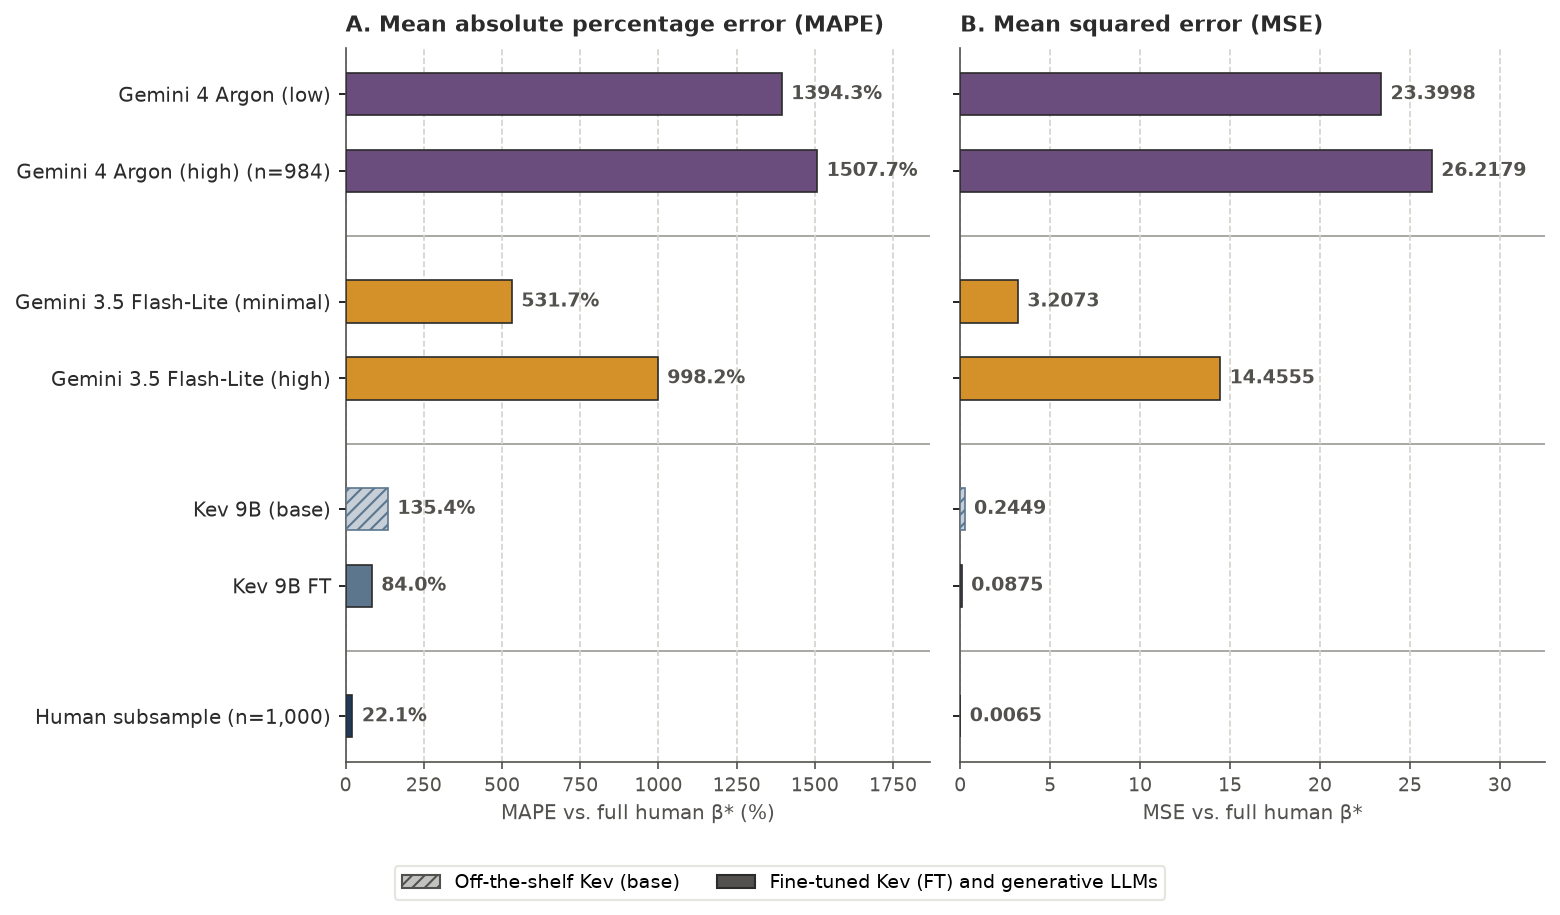

In [17]:
fig_random = plot_wang_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Random Persona",
    bar_groups=ERROR_PLOT_GROUPS,
    group_colors=ERROR_PLOT_COLORS,
    n_sub_sets=n_sub_sets,
)
fig_random.savefig(OUT_DIR / "wang_mnl_random.pdf", bbox_inches="tight")
fig_random.savefig(OUT_DIR / "wang_mnl_random.png", dpi=300, bbox_inches="tight")
print(f"Saved {OUT_DIR / 'wang_mnl_random.pdf'}")
plt.show()

Saved /home/dw/github/decision-models-finetuning/code/analysis/wang2026/wang_mnl_persona.pdf


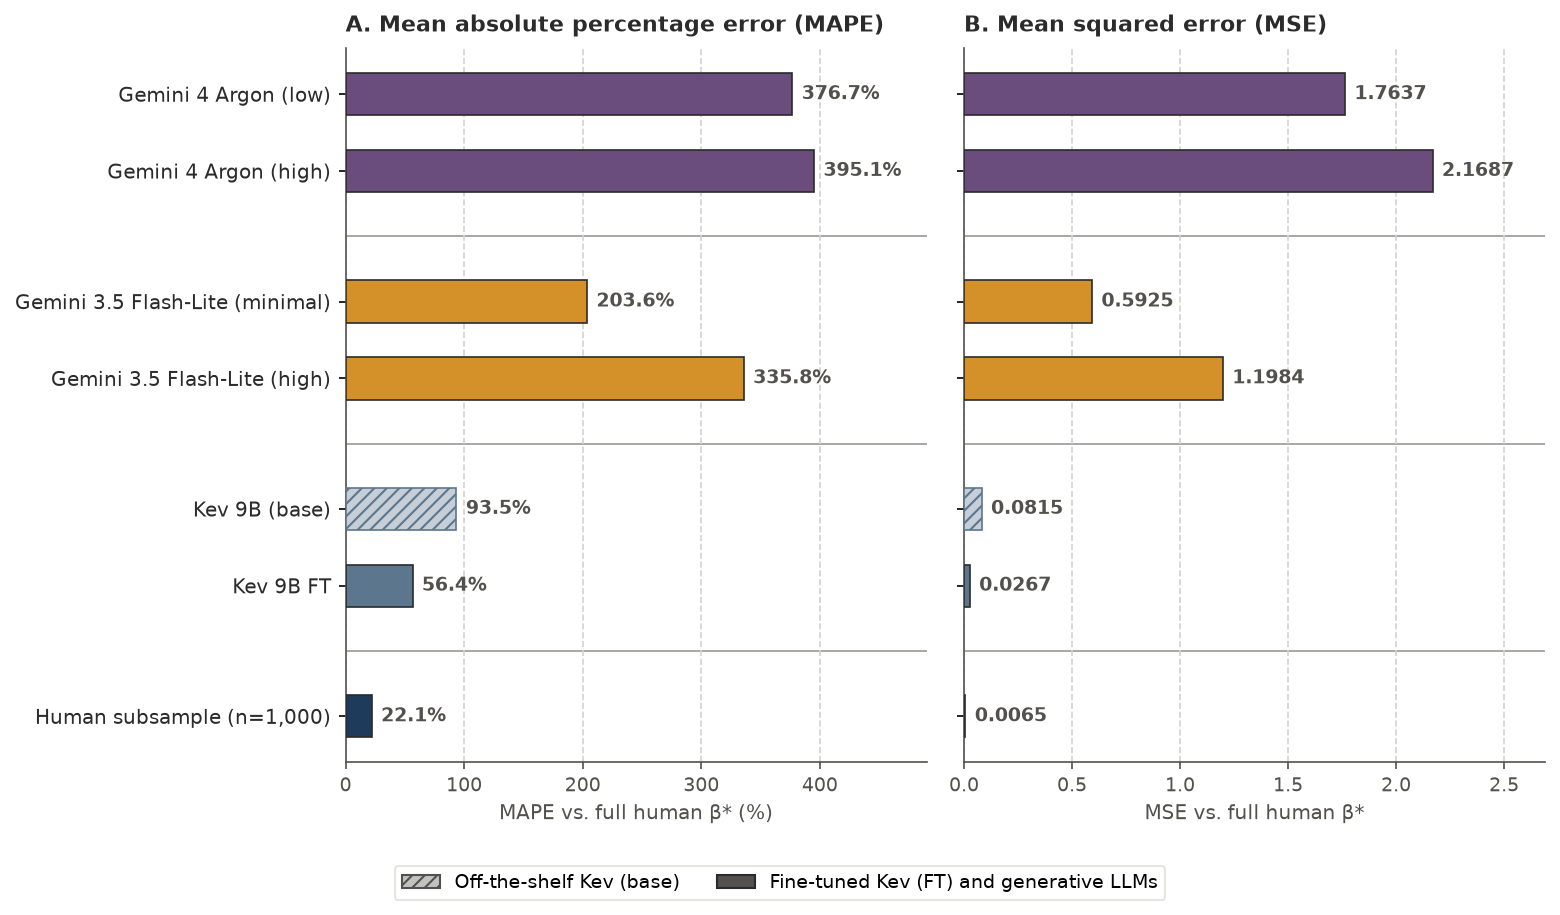

In [18]:
fig_persona = plot_wang_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Respondent Persona",
    bar_groups=ERROR_PLOT_GROUPS,
    group_colors=ERROR_PLOT_COLORS,
    n_sub_sets=n_sub_sets,
)
fig_persona.savefig(OUT_DIR / "wang_mnl_persona.pdf", bbox_inches="tight")
fig_persona.savefig(OUT_DIR / "wang_mnl_persona.png", dpi=300, bbox_inches="tight")
print(f"Saved {OUT_DIR / 'wang_mnl_persona.pdf'}")
plt.show()

## 5. Main-Text Figure: Estimated Part-Worth Coefficients Across Vaccine Attributes (`wang_mnl_coefs.pdf`)

In [19]:
from wang_mnl import MODEL_PALETTES, NEUTRALS, parse_entry_metadata, set_academic_palette


def plot_wang_coefficients(
    human_mnl_df: pd.DataFrame,
    human_sub_mnl_df: pd.DataFrame,
    model_mnl_dfs: dict[str, pd.DataFrame],
    palette: str = "nature",
    persona_mode: str = "Respondent Persona",
    *,
    n_full_sets: int,
    n_sub_sets: int,
) -> plt.Figure:
    """Plot a two-panel forest comparison of the d=11 MNL part-worth coefficients:
    Panel A: Human ground truth vs. off-the-shelf and fine-tuned Kev decision models (with 95% CIs).
    Panel B: Human ground truth and Kev 9B (FT) vs. generative LLMs (showing logit-scale inflation).
    """
    pal = set_academic_palette(palette)
    by_name: dict[str, pd.DataFrame] = {}
    for key, df_m in model_mnl_dfs.items():
        meta = parse_entry_metadata(key)
        if meta["persona"] == persona_mode:
            by_name[str(meta["model"])] = df_m

    kev_base_names = sorted([k for k in by_name if k.startswith("Kev ") and "(base)" in k])
    kev_ft_names = sorted([k for k in by_name if k.startswith("Kev ") and "FT" in k])
    llm_names = sorted([k for k in by_name if not k.startswith("Kev ")])
    if not kev_ft_names or not kev_base_names:
        raise ValueError(f"Expected both base and FT Kev models for {persona_mode}, found {list(by_name.keys())}")

    labels = list(human_mnl_df.index)
    short_labels = [
        lbl.replace("Major side effects: 1 in 1,000,000 (vs. 1 in 10,000)", "Major side effects: 1 in 1M (vs. 1 in 10k)")
           .replace("FDA: Emergency Use Authorization (vs. Full approval)", "FDA: EUA (vs. Full approval)")
           .replace("Origin: United Kingdom (vs. United States)", "Origin: UK (vs. US)")
           .replace("Origin: China (vs. United States)", "Origin: China (vs. US)")
        for lbl in labels
    ]
    y_base = np.arange(len(labels), dtype=np.float64)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.8, 0.65 * len(labels) + 1.6), sharey=True, dpi=150)
    fig.subplots_adjust(wspace=0.10)

    # Panel A series: Full human, Human subsample, Kev base, Kev FT
    panel_a_specs: list[tuple[str, pd.DataFrame, str, str]] = [
        (f"Full human (N = {n_full_sets:,})", human_mnl_df, MODEL_PALETTES[palette]["human"], "o"),
        (f"Human subsample (n = {n_sub_sets:,})", human_sub_mnl_df, NEUTRALS["baseline"], "s"),
    ]
    for kb in kev_base_names:
        panel_a_specs.append((kb, by_name[kb], MODEL_PALETTES[palette]["off_the_shelf"], "^"))
    for kft in kev_ft_names:
        panel_a_specs.append((kft, by_name[kft], MODEL_PALETTES[palette]["fine_tuned"], "D"))

    offsets_a = np.linspace(-0.24, 0.24, len(panel_a_specs))
    ax1.axvline(0.0, color=NEUTRALS["text"], linestyle="-", linewidth=1.4, zorder=2)
    for offset, (name, df_m, color, marker) in zip(offsets_a, panel_a_specs, strict=True):
        betas = df_m.loc[labels, "beta"].to_numpy(dtype=np.float64)
        ses = df_m.loc[labels, "se"].to_numpy(dtype=np.float64)
        ax1.errorbar(
            betas,
            y_base + offset,
            xerr=1.96 * ses,
            fmt=marker,
            color=color,
            ecolor=color,
            elinewidth=1.2,
            capsize=2.2,
            markersize=5.2,
            label=name,
            zorder=3,
        )

    ax1.set_yticks(y_base, labels=short_labels, color=NEUTRALS["text"], fontsize=9.0)
    ax1.invert_yaxis()
    ax1.set_xlabel("Estimated MNL part-worth coefficient β̂ (log-odds)", color=NEUTRALS["muted"], fontsize=9.5)
    ax1.set_title("A. Decision models vs. human ground truth", color=NEUTRALS["text"], fontsize=10.5, fontweight="bold", loc="left", pad=8)
    ax1.tick_params(axis="x", colors=NEUTRALS["muted"], labelsize=9.0)
    ax1.grid(axis="x", color=NEUTRALS["grid"], linestyle="--", linewidth=0.8, zorder=0)
    ax1.spines["top"].set_visible(False)
    ax1.spines["right"].set_visible(False)
    ax1.spines["left"].set_color(NEUTRALS["muted"])
    ax1.spines["bottom"].set_color(NEUTRALS["muted"])
    ax1.legend(
        frameon=True,
        facecolor="white",
        edgecolor=NEUTRALS["legend_edge"],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        ncol=2,
        fontsize=8.5,
    )

    # Panel B series: Full human, best Kev FT, and generative LLMs
    best_kft = kev_ft_names[-1]
    panel_b_specs: list[tuple[str, pd.DataFrame, str, str]] = [
        (f"Full human (N = {n_full_sets:,})", human_mnl_df, MODEL_PALETTES[palette]["human"], "o"),
        (best_kft, by_name[best_kft], MODEL_PALETTES[palette]["fine_tuned"], "D"),
    ]
    llm_colors = [pal[3], pal[4], pal[5], NEUTRALS["baseline"]]
    llm_markers = ["v", "<", ">", "P"]
    for i, llm_name in enumerate(llm_names):
        panel_b_specs.append((
            llm_name,
            by_name[llm_name],
            llm_colors[i % len(llm_colors)],
            llm_markers[i % len(llm_markers)],
        ))

    offsets_b = np.linspace(-0.26, 0.26, len(panel_b_specs))
    ax2.axvline(0.0, color=NEUTRALS["text"], linestyle="-", linewidth=1.4, zorder=2)
    for offset, (name, df_m, color, marker) in zip(offsets_b, panel_b_specs, strict=True):
        betas = df_m.loc[labels, "beta"].to_numpy(dtype=np.float64)
        ses = df_m.loc[labels, "se"].to_numpy(dtype=np.float64)
        ax2.errorbar(
            betas,
            y_base + offset,
            xerr=1.96 * ses,
            fmt=marker,
            color=color,
            ecolor=color,
            elinewidth=1.1,
            capsize=2.0,
            markersize=5.0,
            label=name,
            zorder=3,
        )

    ax2.set_xlabel("Estimated MNL part-worth coefficient β̂ (log-odds)", color=NEUTRALS["muted"], fontsize=9.5)
    ax2.set_title(f"B. Generative LLM scale inflation vs. {best_kft}", color=NEUTRALS["text"], fontsize=10.5, fontweight="bold", loc="left", pad=8)
    ax2.tick_params(axis="x", colors=NEUTRALS["muted"], labelsize=9.0)
    ax2.grid(axis="x", color=NEUTRALS["grid"], linestyle="--", linewidth=0.8, zorder=0)
    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(False)
    ax2.spines["left"].set_color(NEUTRALS["muted"])
    ax2.spines["bottom"].set_color(NEUTRALS["muted"])
    ax2.legend(
        frameon=True,
        facecolor="white",
        edgecolor=NEUTRALS["legend_edge"],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13),
        ncol=2,
        fontsize=8.5,
    )

    plt.tight_layout()
    return fig

Saved /home/dw/github/decision-models-finetuning/code/analysis/wang2026/wang_mnl_coefs.pdf


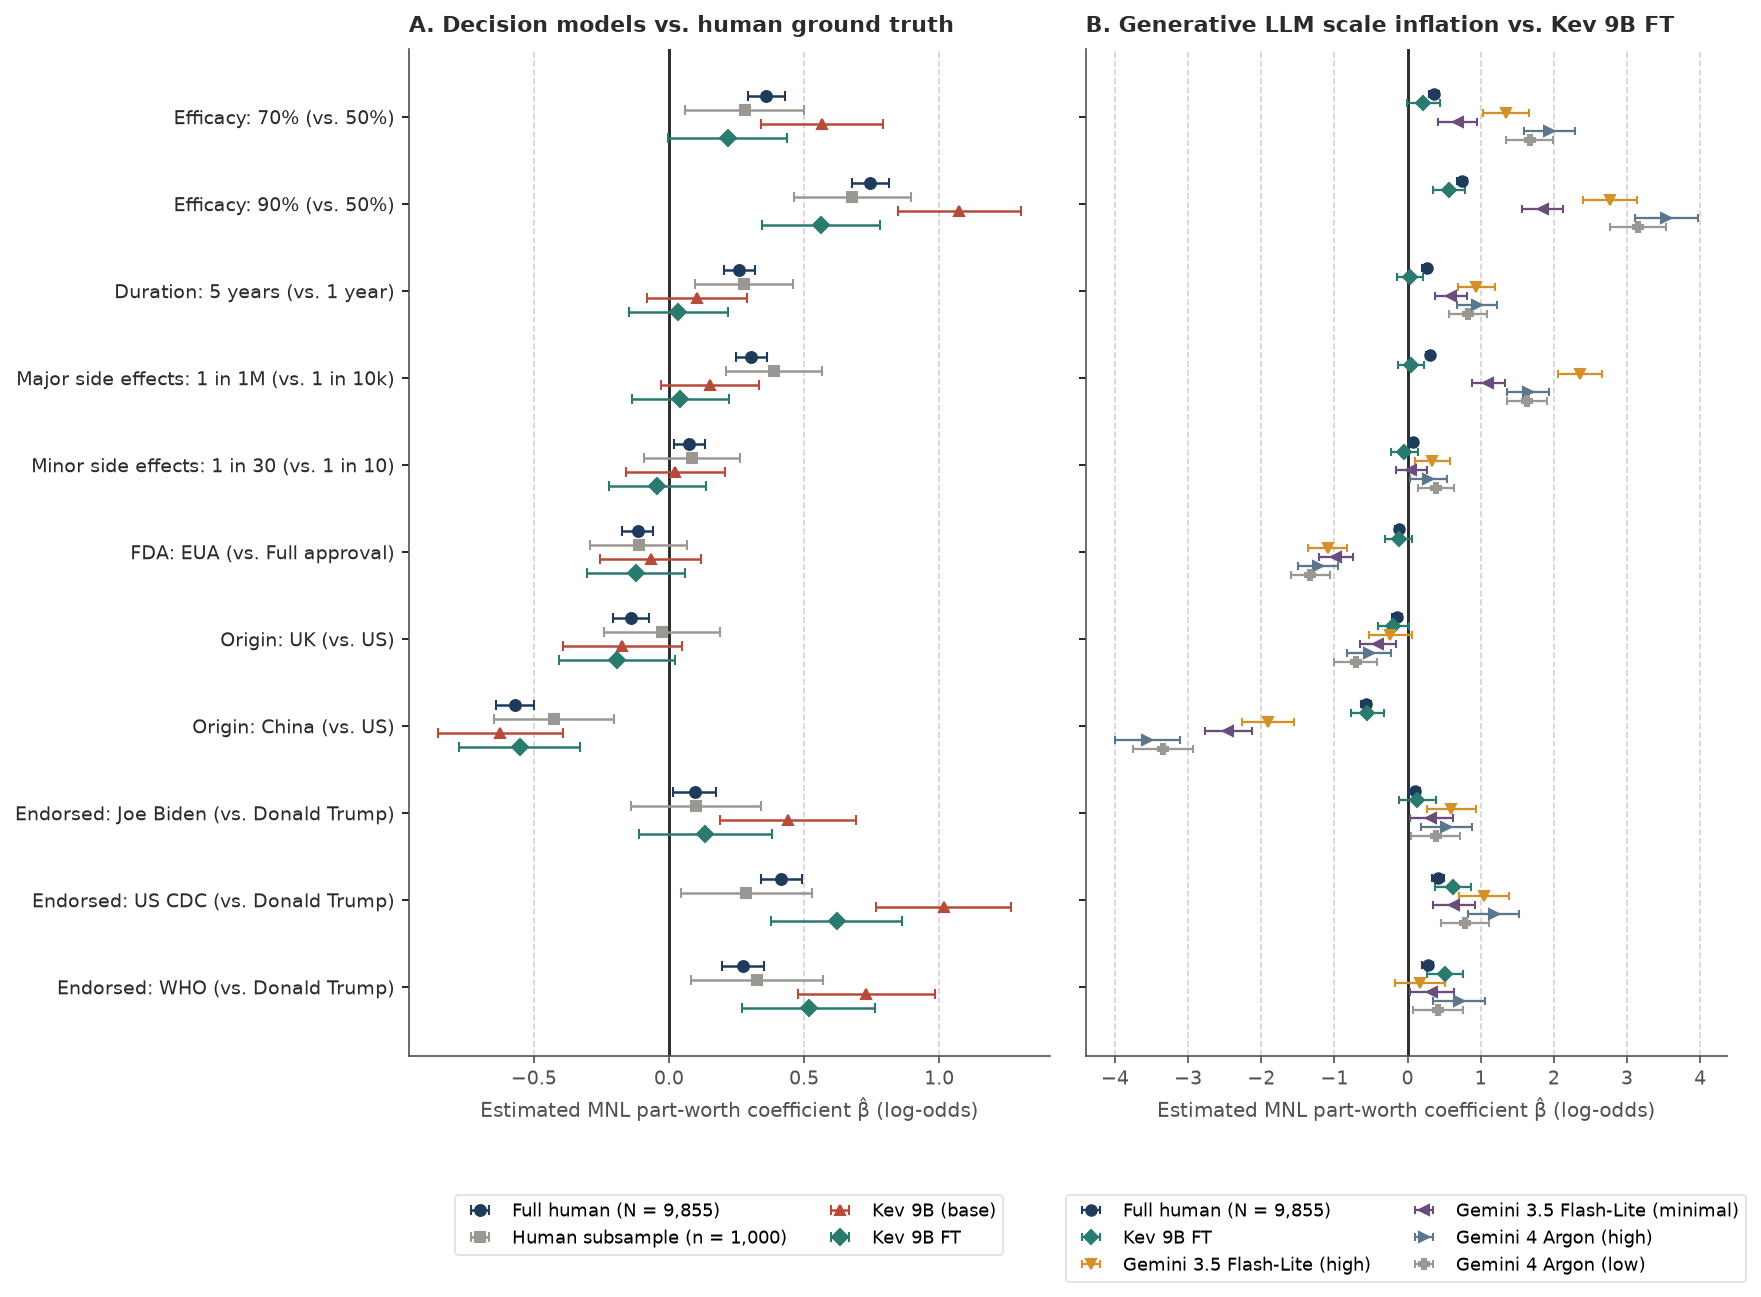

In [20]:
fig_coefs = plot_wang_coefficients(
    human_mnl_df,
    human_sub_mnl_df,
    # figure labels drop the run-set prefix (the plot picks Kev models by names starting with "Kev ")
    {**gemini_mnl_dfs, **{k.removeprefix(FIG_KEV_PREFIX): v for k, v in kev_mnl_dfs_by_prefix[FIG_KEV_PREFIX].items()}},
    palette="nature",
    persona_mode="Respondent Persona",
    n_full_sets=n_full_sets,
    n_sub_sets=n_sub_sets,
)
fig_coefs.savefig(OUT_DIR / "wang_mnl_coefs.pdf", bbox_inches="tight")
fig_coefs.savefig(OUT_DIR / "wang_mnl_coefs.png", dpi=300, bbox_inches="tight")
print(f"Saved {OUT_DIR / 'wang_mnl_coefs.pdf'}")
plt.show()

## 6. Web Appendix Table: Attribute-Level MNL Part-Worth Estimates (`#apptbl-wang-coefs`)

In [9]:
apptbl_coefs_df = build_wang_coef_table(
    human_mnl_df,
    human_sub_mnl_df,
    model_mnl_dfs,
    persona_mode="Respondent Persona",
    n_full_sets=n_full_sets,
    n_sub_sets=n_sub_sets,
)
display(apptbl_coefs_df)

print('::: {#apptbl-wang-coefs size="scriptsize"}\n')
print(to_paper_md(apptbl_coefs_df))
print("\nEstimated multinomial logit part-worth coefficients on the COVID-19 vaccine conjoint benchmark\n")
print(":::\n")
print('::: {custom-style="Table Note"}')
print(
    f"*Note.* Point estimates and asymptotic standard errors (in parentheses) across the {d_attr} binary vaccine attribute indicators "
    f"on the {n_sub_resp}-respondent subsample (*n* = {n_sub_sets:,} choice sets) under respondent-persona conditioning, alongside "
    f"full-sample human estimates (*N* = {n_full_resp:,} respondents, {n_full_sets:,} choice sets; @kreps2020factors; @wang2026large). "
    f"{persona_txt}. {wording_txt[0].upper() + wording_txt[1:]}."
)
print(":::")

,Vaccine attribute level,"Full human (N = 9,855)","Human subsample (n = 1,000)",Kev 9B FT,Kev 9B (base),Gemini 3.5 Flash-Lite (high),Gemini 3.5 Flash-Lite (minimal),Gemini 4 Argon (high),Gemini 4 Argon (low)
0,Efficacy: 70% (vs. 50%),+0.361 (0.035),+0.280 (0.112),+0.217 (0.113),+0.565 (0.115),+1.344 (0.158),+0.688 (0.135),+1.940 (0.176),+1.671 (0.163)
1,Efficacy: 90% (vs. 50%),+0.746 (0.035),+0.679 (0.110),+0.562 (0.111),+1.074 (0.116),+2.764 (0.188),+1.846 (0.145),+3.538 (0.218),+3.148 (0.196)
2,Duration: 5 years (vs. 1 year),+0.261 (0.029),+0.277 (0.092),+0.035 (0.093),+0.105 (0.095),+0.940 (0.131),+0.592 (0.114),+0.948 (0.140),+0.830 (0.133)
3,"Major side effects: 1 in 1,000,000 (vs. 1 in 1...",+0.304 (0.029),+0.389 (0.091),+0.043 (0.092),+0.152 (0.093),+2.353 (0.154),+1.103 (0.114),+1.647 (0.146),+1.634 (0.140)
4,Minor side effects: 1 in 30 (vs. 1 in 10),+0.076 (0.029),+0.085 (0.090),-0.043 (0.092),+0.024 (0.093),+0.341 (0.124),+0.051 (0.109),+0.282 (0.128),+0.389 (0.124)
5,FDA: Emergency Use Authorization (vs. Full app...,-0.115 (0.029),-0.113 (0.092),-0.123 (0.093),-0.068 (0.095),-1.089 (0.136),-0.978 (0.115),-1.223 (0.141),-1.329 (0.137)
6,Origin: United Kingdom (vs. United States),-0.140 (0.035),-0.026 (0.109),-0.192 (0.110),-0.173 (0.113),-0.234 (0.151),-0.402 (0.127),-0.527 (0.157),-0.710 (0.151)
7,Origin: China (vs. United States),-0.570 (0.036),-0.425 (0.113),-0.553 (0.114),-0.624 (0.118),-1.908 (0.179),-2.449 (0.164),-3.556 (0.227),-3.341 (0.210)
8,Endorsed: Joe Biden (vs. Donald Trump),+0.095 (0.040),+0.100 (0.123),+0.135 (0.126),+0.441 (0.128),+0.600 (0.171),+0.325 (0.148),+0.531 (0.178),+0.385 (0.170)
9,Endorsed: US CDC (vs. Donald Trump),+0.416 (0.039),+0.287 (0.123),+0.621 (0.124),+1.017 (0.127),+1.045 (0.172),+0.635 (0.148),+1.175 (0.179),+0.784 (0.169)


::: {#apptbl-wang-coefs size="scriptsize"}

| Vaccine attribute level | Full human (*N* = 9,855) | Human subsample (*n* = 1,000) | Kev 9B FT | Kev 9B (base) | Gemini 3.5 Flash-Lite (high) | Gemini 3.5 Flash-Lite (minimal) | Gemini 4 Argon (high) | Gemini 4 Argon (low) |
|:---|---:|---:|---:|---:|---:|---:|---:|---:|
| Efficacy: 70% (vs. 50%) | +0.361 (0.035) | +0.280 (0.112) | +0.217 (0.113) | +0.565 (0.115) | +1.344 (0.158) | +0.688 (0.135) | +1.940 (0.176) | +1.671 (0.163) |
| Efficacy: 90% (vs. 50%) | +0.746 (0.035) | +0.679 (0.110) | +0.562 (0.111) | +1.074 (0.116) | +2.764 (0.188) | +1.846 (0.145) | +3.538 (0.218) | +3.148 (0.196) |
| Duration: 5 years (vs. 1 year) | +0.261 (0.029) | +0.277 (0.092) | +0.035 (0.093) | +0.105 (0.095) | +0.940 (0.131) | +0.592 (0.114) | +0.948 (0.140) | +0.830 (0.133) |
| Major side effects: 1 in 1,000,000 (vs. 1 in 10,000) | +0.304 (0.029) | +0.389 (0.091) | +0.043 (0.092) | +0.152 (0.093) | +2.353 (0.154) | +1.103 (0.114) | +1.647 (0.146) | +1.634 